In [1]:
import torch
from utilities import (
    set_seed, load_and_combine_datasets, create_dataloaders,
    get_single_model, train_model, test_and_report, visualize_gradcam_samples, load_trained_model
)

# 1. Setup

In [2]:
set_seed(42)
device = torch.device("cpu")

# 2. Data

In [3]:
df = load_and_combine_datasets()
train_loader, val_loader, test_loader, test_ds = create_dataloaders(df, batch_size=16)

[Dataset] Loaded 368 images total.
[Splits] Train: 257 | Val: 55 | Test: 56


# 3. Choose your model: 
    1. resnet50 
    2. vgg16_bn 
    3. densenet121 
    4. efficientnet_b0

In [4]:
MODEL_NAME = "resnet50"
model, target_layer = get_single_model(MODEL_NAME, freeze_backbone=True)

[RESNET50] Total: 24,033,602 | Trainable: 525,570 (2.19%)


# 4. Train Single Model

In [5]:
model, history = train_model(
    model, train_loader, val_loader, device, 
    epochs=30, lr=1e-3, model_name=MODEL_NAME, resume=True
)

Epoch [01/30] Train Loss: 0.5470 Acc: 0.7617 | Val Loss: 0.5077 Acc: 0.8000 (Best: 0.8000)
Epoch [02/30] Train Loss: 0.3115 Acc: 0.8789 | Val Loss: 0.3254 Acc: 0.8364 (Best: 0.8364)
Epoch [03/30] Train Loss: 0.2534 Acc: 0.9219 | Val Loss: 0.1693 Acc: 0.9818 (Best: 0.9818)
Epoch [04/30] Train Loss: 0.1956 Acc: 0.9375 | Val Loss: 0.1791 Acc: 0.9273 (Best: 0.9818)
Epoch [05/30] Train Loss: 0.1641 Acc: 0.9531 | Val Loss: 0.1444 Acc: 0.9455 (Best: 0.9818)
Epoch [06/30] Train Loss: 0.1389 Acc: 0.9570 | Val Loss: 0.1457 Acc: 0.9455 (Best: 0.9818)
Epoch [07/30] Train Loss: 0.1072 Acc: 0.9766 | Val Loss: 0.1114 Acc: 0.9636 (Best: 0.9818)
Epoch [08/30] Train Loss: 0.1682 Acc: 0.9258 | Val Loss: 0.0880 Acc: 0.9636 (Best: 0.9818)
Epoch [09/30] Train Loss: 0.0927 Acc: 0.9727 | Val Loss: 0.1063 Acc: 0.9455 (Best: 0.9818)
Epoch [10/30] Train Loss: 0.1454 Acc: 0.9453 | Val Loss: 0.1267 Acc: 0.9455 (Best: 0.9818)
Epoch [11/30] Train Loss: 0.1255 Acc: 0.9453 | Val Loss: 0.1515 Acc: 0.9455 (Best: 0.9818)

# 5. Evaluate Single Model on Test Set


==================== RESNET50 TEST RESULTS ====================
Loss: 0.1283 | Accuracy: 98.21%
Sensitivity (Recall): 100.00% | Specificity: 96.55%
Precision: 96.43% | F1-Score: 0.9818 | ROC-AUC: 1.0000


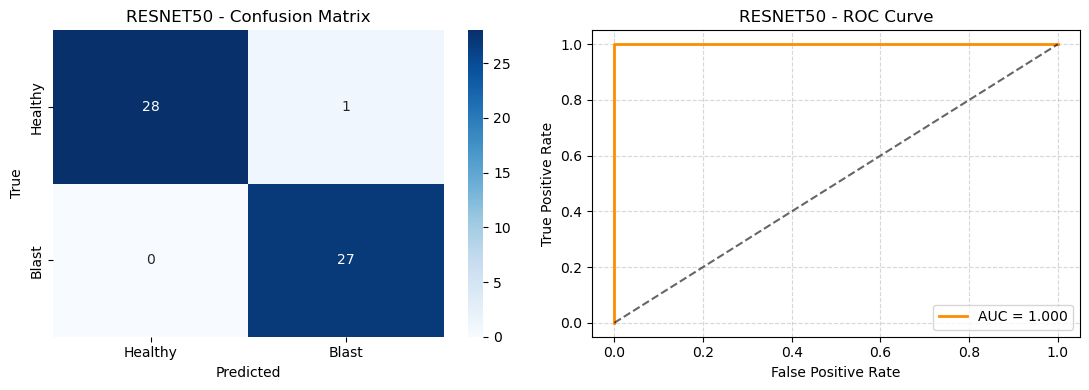

In [6]:
metrics = test_and_report(model, test_loader, device, model_name=MODEL_NAME)

# 6. Explainability with Grad-CAM

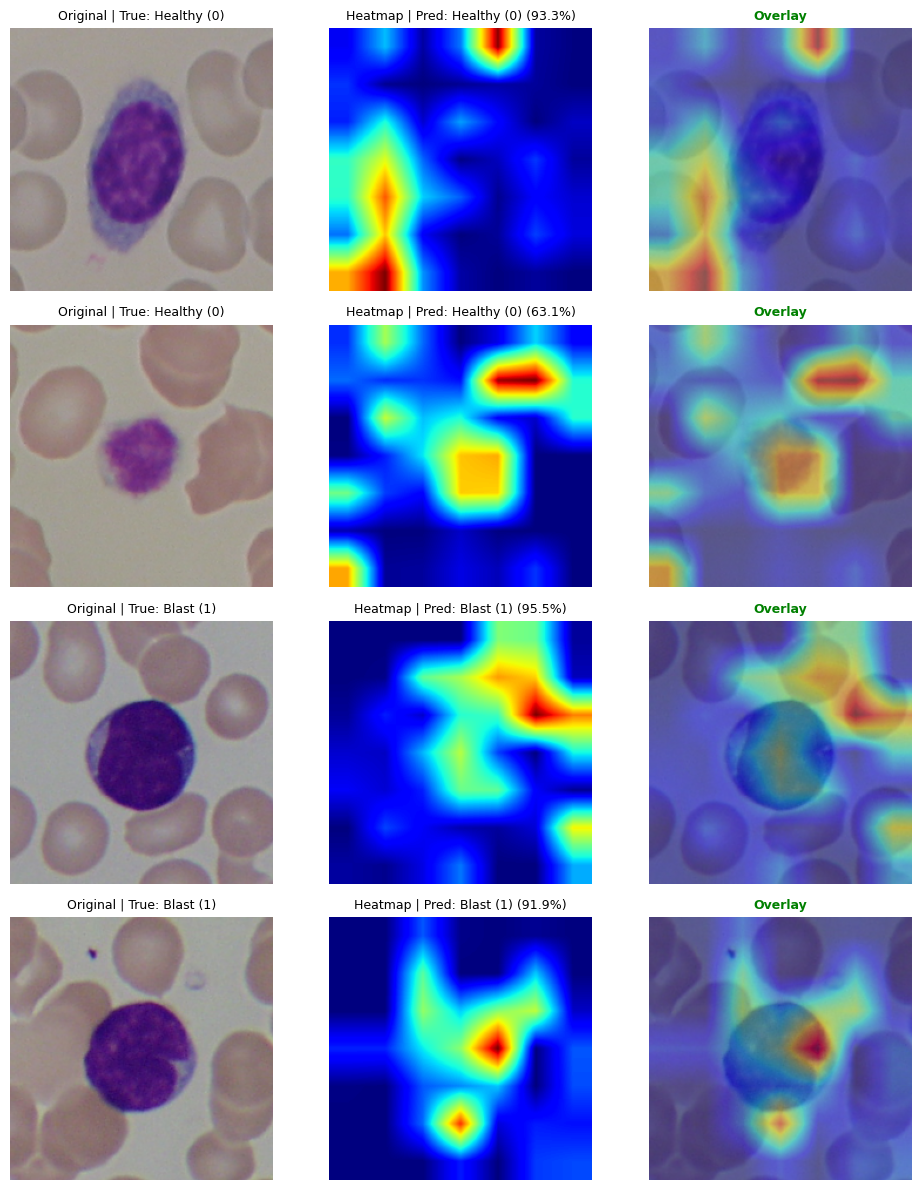

In [7]:
visualize_gradcam_samples(model, target_layer, test_ds, device, num_samples=4)